# **VISIÓN COMPUTACIONAL**
- Luis Fernando Gallegos Ballon
- Eddy Arnold Cruz Ccanchi

# 1. Librerias usadas

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt
from google.colab import files

#2. Cargar imagen del dataset

In [ ]:
up = files.upload()
imgs = {}
for name, data in up.items():
    im = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    s = 960 / im.shape[1]
    imgs[name] = cv2.resize(im, (960, int(im.shape[0]*s)))
print(len(imgs), "imágenes cargadas")

Saving n02105855_142.jpg to n02105855_142.jpg
Saving n02105855_154.jpg to n02105855_154.jpg
Saving n02105855_190.jpg to n02105855_190.jpg
Saving n02105855_742.jpg to n02105855_742.jpg
Saving n02105855_982.jpg to n02105855_982.jpg
Saving n02105855_1013.jpg to n02105855_1013.jpg
Saving n02105855_1791.jpg to n02105855_1791.jpg
Saving n02105855_1816.jpg to n02105855_1816.jpg
Saving n02105855_1963.jpg to n02105855_1963.jpg
Saving n02105855_2039.jpg to n02105855_2039.jpg
Saving n02105855_2094.jpg to n02105855_2094.jpg
Saving n02105855_2172.jpg to n02105855_2172.jpg
Saving n02105855_2376.jpg to n02105855_2376.jpg
Saving n02105855_2433.jpg to n02105855_2433.jpg
Saving n02105855_2853.jpg to n02105855_2853.jpg
Saving n02105855_2933.jpg to n02105855_2933.jpg
Saving n02105855_3103.jpg to n02105855_3103.jpg
Saving n02105855_3150.jpg to n02105855_3150.jpg
Saving n02105855_3168.jpg to n02105855_3168.jpg
Saving n02105855_3255.jpg to n02105855_3255.jpg
Saving n02105855_3292.jpg to n02105855_3292.jpg
Sa

#3. Lista de filtros


In [ ]:
# --- Conversión / tonales ---
def to_gray(img):
    # Sin parámetros. Si la imagen ya es gris, la devuelve igual.
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def brightness(img, beta=30):
    # beta: entero de -255 a 255. > 0 aclara, < 0 oscurece, 0 no cambia.
    # Valores útiles: -60 a 60.
    return cv2.convertScaleAbs(img, alpha=1.0, beta=beta)

def clahe(img, clip=2.0, tile=8):
    # clip: límite de contraste (1.0 a 4.0). Más alto = más contraste local y más ruido.
    # tile: la imagen se divide en tile x tile zonas (4, 8, 16).
    c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    if img.ndim == 2:
        return c.apply(img)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    lab[..., 0] = c.apply(lab[..., 0])     # solo el canal de luminosidad
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

# --- Suavizado ---
def median_filter(img, k=5):
    # k: tamaño de ventana, debe ser IMPAR y mayor que 1 (3, 5, 7...).
    # Para sal y pimienta: 3 (leve), 5 (medio), 7 (fuerte). Más grande pierde detalle.
    return cv2.medianBlur(img, k)

def bilateral_filter(img, d=9, sigma_color=75, sigma_space=75):
    # d: diámetro del vecindario en píxeles. 5 = rápido, 9 = ruido fuerte (más lento).
    # sigma_color: cuánta diferencia de color se mezcla. 10-150: bajo conserva bordes, alto suaviza más.
    # sigma_space: alcance espacial de la mezcla. 10-150: alto = mezcla píxeles más lejanos.
    return cv2.bilateralFilter(img, d, sigma_color, sigma_space)

# --- Bordes ---
def sobel_filter(img, k=3, dx=1, dy=1):
    # k: tamaño del kernel, impar: 1, 3, 5, 7. 3 es el estándar; más grande detecta bordes más gruesos.
    # dx, dy: 1 = calcula el gradiente en esa dirección, 0 = no.
    #         (1,0) solo bordes verticales, (0,1) solo horizontales, (1,1) ambos combinados.
    g = to_gray(img)
    gx = cv2.Sobel(g, cv2.CV_64F, 1, 0, ksize=k) if dx else 0
    gy = cv2.Sobel(g, cv2.CV_64F, 0, 1, ksize=k) if dy else 0
    mag = np.sqrt(np.square(gx) + np.square(gy))
    return cv2.convertScaleAbs(mag)

#4. Pipeline de preprocesamiento

In [ ]:
CFG = dict(
    k_median=3,                   # sal y pimienta
    d=9, s_color=75, s_space=75,  # bilateral
    brillo=10,                    # (Opcional: un ajuste leve de brillo base es válido)
    clip_clahe=2.0,               # límite de contraste adaptativo local
    tile_clahe=8,                 # cuadrícula de zonas (4, 8, 16)
    k_sobel=3,
)

def pipeline(img, cfg=CFG):
    st = {"original": img}

    # 1. Corrección de ruido (Excelente: Mediana quita picos, Bilateral suaviza respetando bordes)
    x = median_filter(img, cfg["k_median"])
    x = bilateral_filter(x, cfg["d"], cfg["s_color"], cfg["s_space"])
    st["Ruido Corregido"] = x

    # 2. Iluminación y Ecualización Adaptativa (Sin contraste lineal redundante)
    x = brightness(x, cfg["brillo"])
    x = clahe(x, cfg["clip_clahe"], cfg["tile_clahe"])
    st["CLAHE"] = x

    # 3. Detección de Bordes
    x = sobel_filter(x, cfg["k_sobel"])
    st["Sobel"] = x

    return st

results = {n: pipeline(im) for n, im in imgs.items()}


#5. Comparación y resulttados

In [ ]:
def rgb(im):
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im

def show(name, stages=None, ncols=3, size=4.5):
    st = results[name]; keys = stages or list(st.keys())
    nrows = -(-len(keys) // ncols)
    fig, ax = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.8))
    axs = np.atleast_1d(ax).ravel()
    for a in axs: a.axis("off")
    for a, k in zip(axs, keys):
        a.imshow(rgb(st[k]), cmap="gray"); a.set_title(k, fontsize=10)
    fig.suptitle(name); plt.tight_layout(); plt.show()

def comparar(titulo, col_derecha, titulo_derecha):
    fig, axs = plt.subplots(len(imgs), 2, figsize=(8, 4 * len(imgs)))
    axs = np.atleast_2d(axs)
    for r, n in enumerate(imgs):
        axs[r][0].imshow(rgb(imgs[n]), cmap="gray"); axs[r][0].set_title("Original", fontsize=10)
        axs[r][1].imshow(col_derecha(n), cmap="gray"); axs[r][1].set_title(titulo_derecha, fontsize=10)
        axs[r][0].set_ylabel(n[:16]); axs[r][0].set_xticks([]); axs[r][0].set_yticks([])
        axs[r][1].axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

def metricas(im, umbral_borde=50):
    g = to_gray(im)
    hist = np.bincount(g.ravel(), minlength=256) / g.size
    p = hist[hist > 0]
    return {
        "brillo":    g.mean(),                               # media de intensidad
        "contraste": g.std(),                                # desviación estándar
        "nitidez":   cv2.Laplacian(g, cv2.CV_64F).var(),     # varianza del Laplaciano
        "entropia":  -(p * np.log2(p)).sum(),                # información (0 a 8)
        "bordes_%":  100 * (g > umbral_borde).mean(),        # % de píxeles con borde fuerte
    }

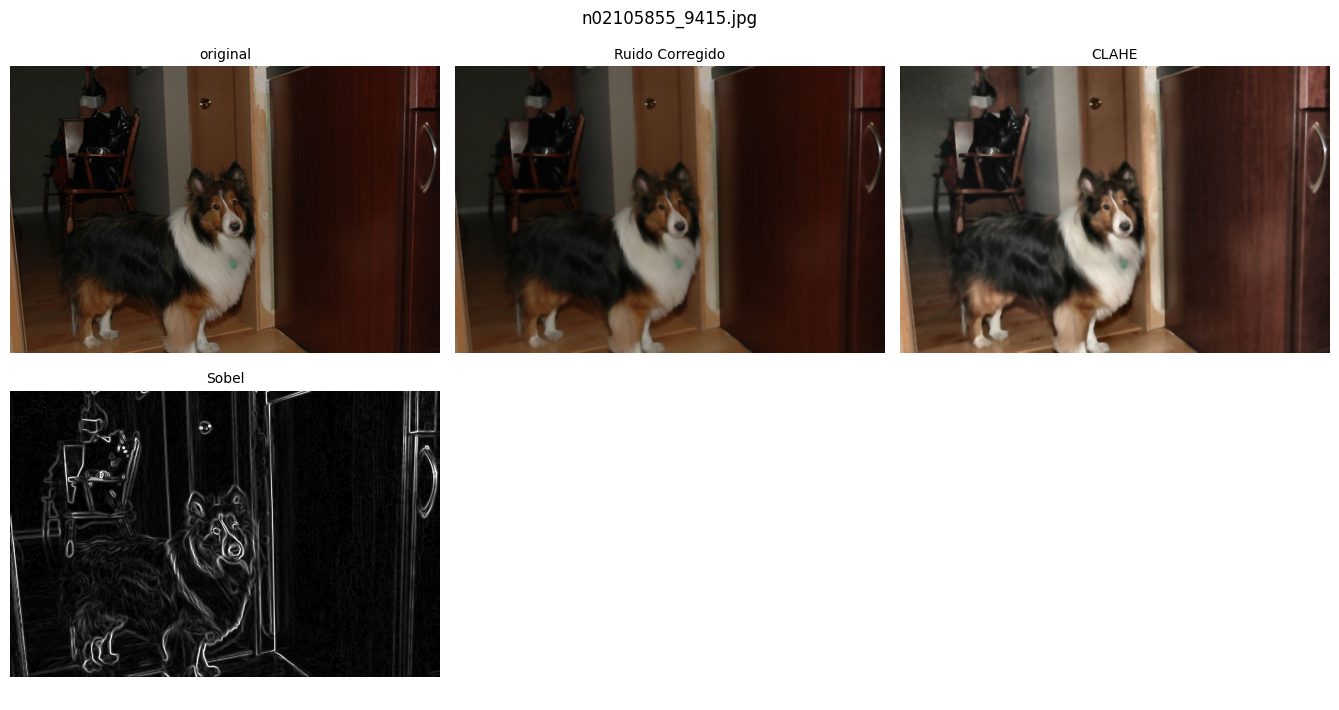

In [ ]:
# 4.1 Paso a paso en la imagen más oscura
oscura = min(imgs, key=lambda n: to_gray(imgs[n]).mean())
show(oscura)

In [ ]:
# 4.5 Histogramas
CLAHE_KEY = "CLAHE"
fig, axs = plt.subplots(len(imgs), 2, figsize=(15, 3.5 * len(imgs)))
axs = np.atleast_2d(axs)
for r, n in enumerate(imgs):
    h = lambda im: cv2.calcHist([to_gray(im)], [0], None, [256], [0, 256]).ravel()
    # (a) Efecto de la iluminación: original vs CLAHE
    axs[r][0].plot(h(imgs[n]), color="#999", label="Original")
    axs[r][0].plot(h(results[n][CLAHE_KEY]), color="#2a9d8f", label="Tras CLAHE")
    axs[r][0].set_title("Histograma: original vs CLAHE", fontsize=10); axs[r][0].legend()
    # (b) Histograma acumulado de la imagen original vs CLAHE
    for im, c, l in [(imgs[n], "#999", "Original"), (results[n][CLAHE_KEY], "#2a9d8f", "Tras CLAHE")]:
        cdf = np.cumsum(h(im)); axs[r][1].plot(cdf / cdf[-1], color=c, label=l)
    axs[r][1].set_title("Histograma acumulado", fontsize=10); axs[r][1].legend()
    axs[r][0].set_ylabel(n[:16])
plt.tight_layout(); plt.show()

,original,sobel_pipeline
brillo,111.70,35.95
contraste,58.19,41.35
nitidez,125.92,1665.99
entropia,7.45,6.28
bordes_%,78.77,20.31


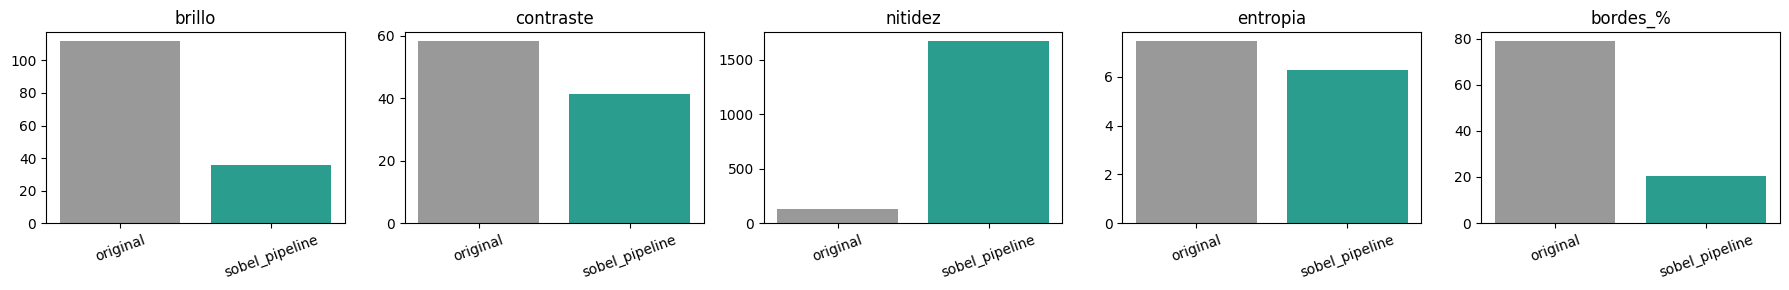

In [ ]:
# 4.6 Métricas: original vs Sobel con pipeline
import pandas as pd
from IPython.display import display

etapas = {
    "original":       lambda n: imgs[n],
    "sobel_pipeline": lambda n: results[n]["Sobel"],
}

rows = []
for n in imgs:
    fila = {"archivo": n}
    for etapa, f in etapas.items():
        fila.update({f"{k}_{etapa}": v for k, v in metricas(f(n)).items()})
    rows.append(fila)
comp = pd.DataFrame(rows)


cols = ["brillo", "contraste", "nitidez", "entropia", "bordes_%"]
res = pd.DataFrame({e: [comp[f"{c}_{e}"].mean() for c in cols] for e in etapas}, index=cols).round(2)
display(res)

fig, axs = plt.subplots(1, len(cols), figsize=(18, 3))
for a, c in zip(axs, cols):
    a.bar(list(etapas), res.loc[c], color=["#999", "#2a9d8f"])
    a.set_title(c); a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()